In [65]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf

T = 10
N = 1000
dt = T / N
t = np.linspace(0, T, N+1)
np.random.seed(0)

# Browniano estándar
dW = np.sqrt(dt) * np.random.randn(N)
W = np.concatenate(([0], np.cumsum(dW)))

def euler_maruyama(mu, sigma, x0=0):
    X = np.zeros(N+1)
    X[0] = x0
    for i in range(N):
        X[i+1] = X[i] + mu(t[i], X[i]) * dt + sigma(t[i]) * dW[i]
    return X


##### Caso 1: $\mu$ y $\sigma$ constantes

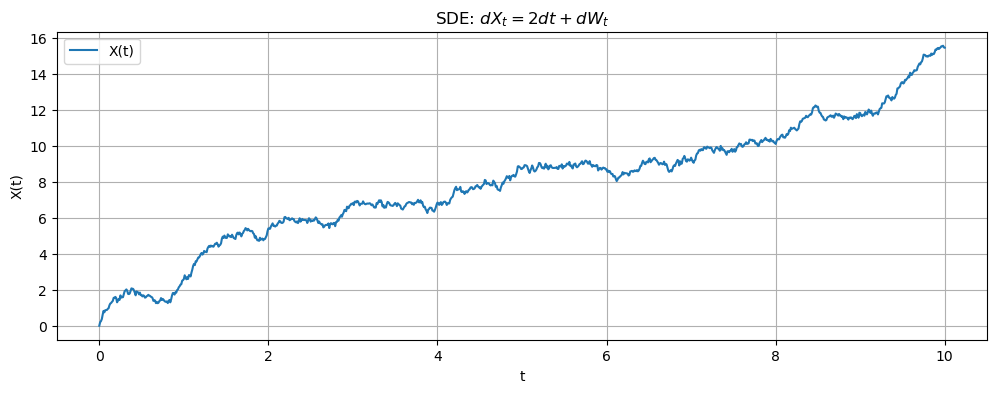

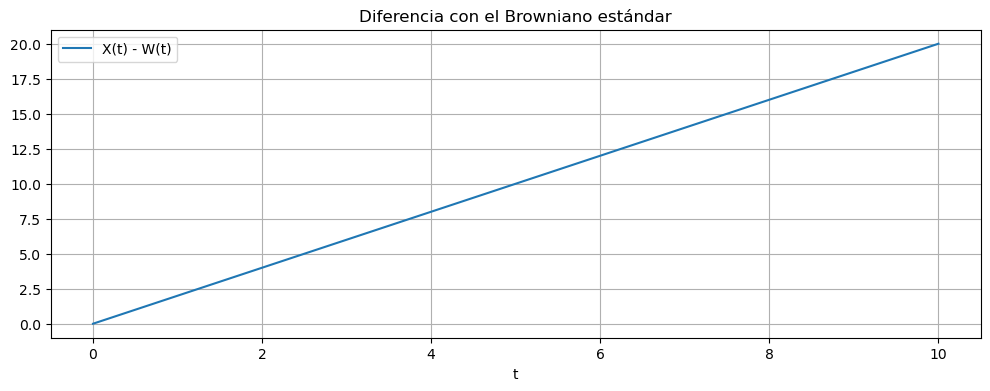

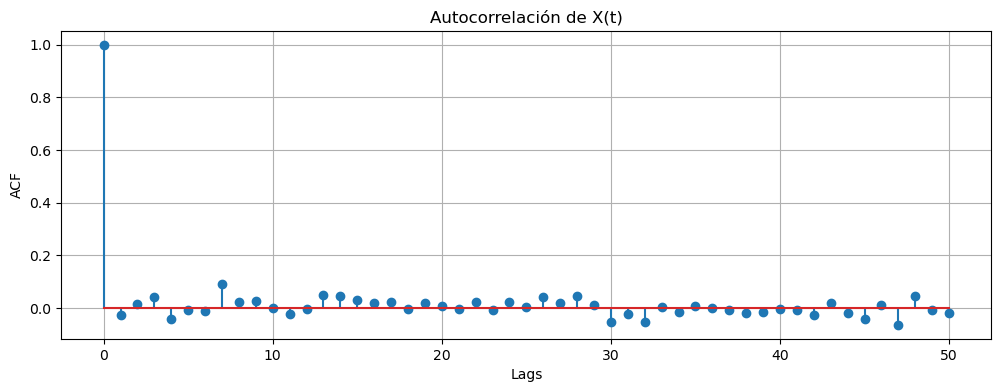

In [66]:
mu_const = lambda t, x: 2
sigma_const = lambda t: 1

X = euler_maruyama(mu_const, sigma_const)

# Trayectoria simulada
plt.figure(figsize=(12, 4))
plt.plot(t, X, label = 'X(t)')
plt.title("SDE: $dX_t = 2 dt + d W_t$")
plt.xlabel("t")
plt.ylabel("X(t)")
plt.grid(True)
plt.legend()
plt.show()

# Diferencia con Browniano estándar
plt.figure(figsize=(12, 4))
plt.plot(t, X - W, label='X(t) - W(t)')
plt.title("Diferencia con el Browniano estándar")
plt.xlabel('t')
plt.grid(True)
plt.legend()
plt.show()

# Autocorrelación
acf_vals = acf(np.diff(X), nlags=50)
plt.figure(figsize=(12, 4))
plt.stem(range(len(acf_vals)), acf_vals)
plt.title("Autocorrelación de X(t)")
plt.xlabel("Lags")
plt.ylabel("ACF")
plt.grid(True)
plt.show()

##### Caso 2: $\mu(t) = \sin{(2\pi t)}$, $\sigma = 1$

<>:9: SyntaxWarning: invalid escape sequence '\s'
<>:9: SyntaxWarning: invalid escape sequence '\s'
C:\Users\franc\AppData\Local\Temp\ipykernel_22704\78191749.py:9: SyntaxWarning: invalid escape sequence '\s'
  plt.title("SDE: $dX_t = \sin{(2\pi t)} dt + d W_t$")


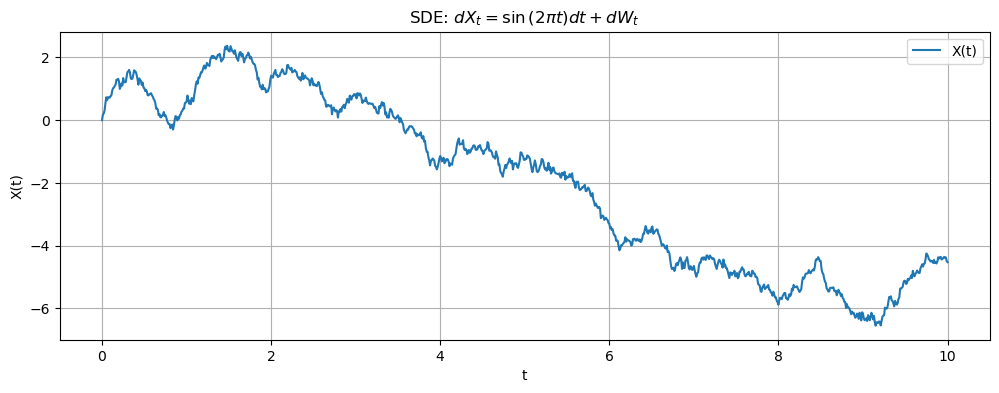

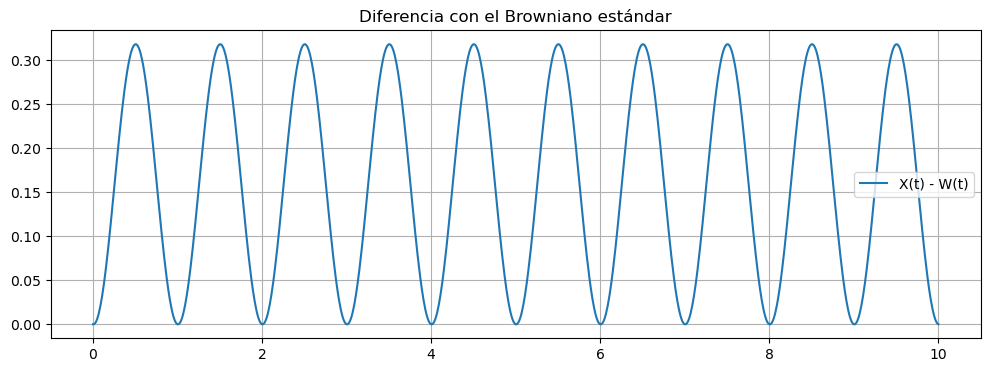

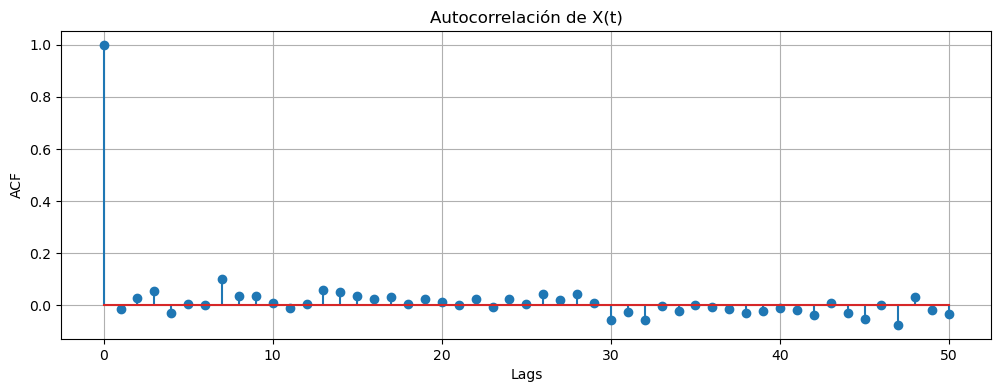

In [67]:
mu_t = lambda t, x: np.sin(2 * np.pi * t)
sigma_const = lambda t: 1

X = euler_maruyama(mu_t, sigma_const)

# Trayectoria simulada
plt.figure(figsize=(12, 4))
plt.plot(t, X, label = 'X(t)')
plt.title("SDE: $dX_t = \sin{(2\pi t)} dt + d W_t$")
plt.xlabel("t")
plt.ylabel("X(t)")
plt.grid(True)
plt.legend()
plt.show()

# Diferencia con Browniano estándar
plt.figure(figsize=(12, 4))
plt.plot(t, X - W, label='X(t) - W(t)')
plt.title("Diferencia con el Browniano estándar")
plt.grid(True)
plt.legend()
plt.show()

# Autocorrelación
acf_vals = acf(np.diff(X), nlags=50)
plt.figure(figsize=(12, 4))
plt.stem(range(len(acf_vals)), acf_vals)
plt.title("Autocorrelación de X(t)")
plt.xlabel("Lags")
plt.ylabel("ACF")
plt.grid(True)
plt.show()

##### Caso 3: $\mu(x) = x$, $\sigma = 1$

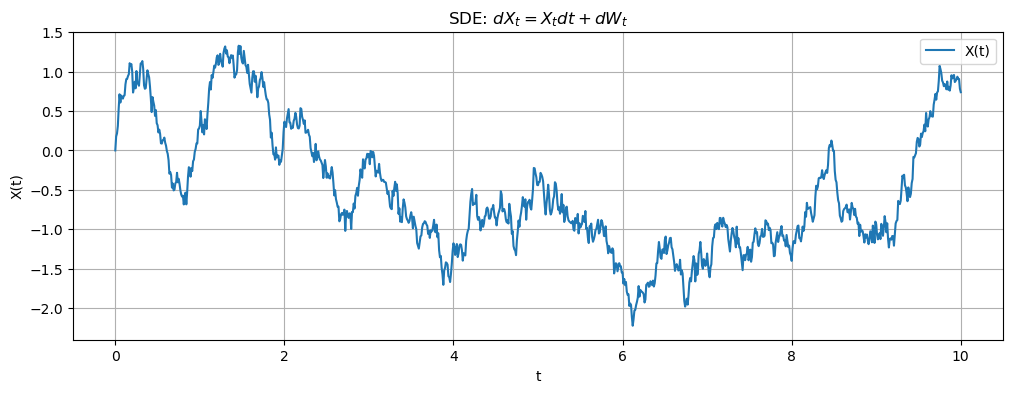

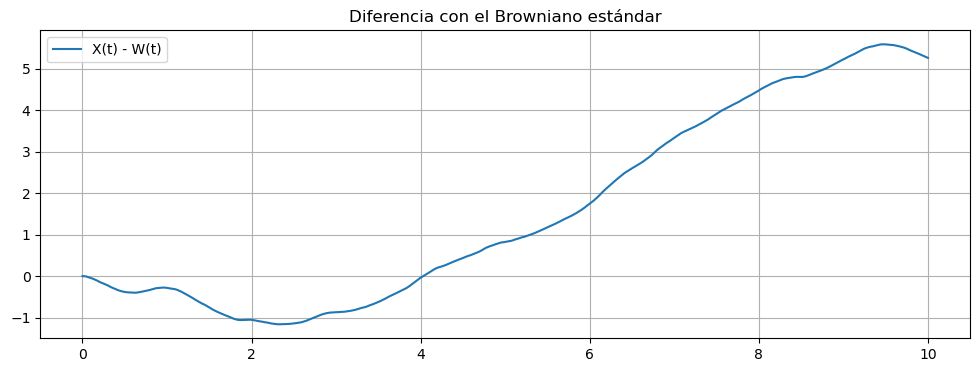

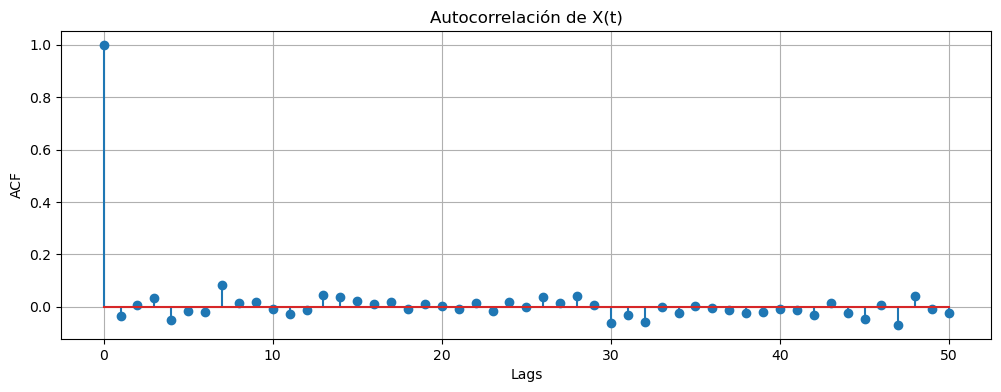

In [75]:
mu_x = lambda t, x: -x
sigma_const = lambda t: 1

X = euler_maruyama(mu_x, sigma_const)

# Trayectoria simulada
plt.figure(figsize=(12, 4))
plt.plot(t, X, label = 'X(t)')
plt.title("SDE: $dX_t = X_t dt + d W_t$")
plt.xlabel("t")
plt.ylabel("X(t)")
plt.grid(True)
plt.legend()
plt.show()

# Diferencia con Browniano estándar
plt.figure(figsize=(12, 4))
plt.plot(t, X - W, label='X(t) - W(t)')
plt.title("Diferencia con el Browniano estándar")
plt.grid(True)
plt.legend()
plt.show()

# Autocorrelación
acf_vals = acf(np.diff(X), nlags=50)
plt.figure(figsize=(12, 4))
plt.stem(range(len(acf_vals)), acf_vals)
plt.title("Autocorrelación de X(t)")
plt.xlabel("Lags")
plt.ylabel("ACF")
plt.grid(True)
plt.show()

##### Caso 4: $\mu(x,t) = e^{-tx}$, $\sigma = 1$

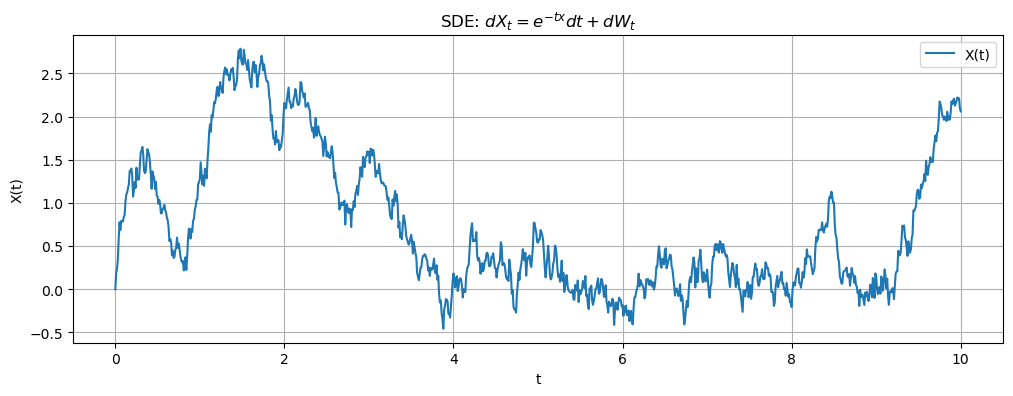

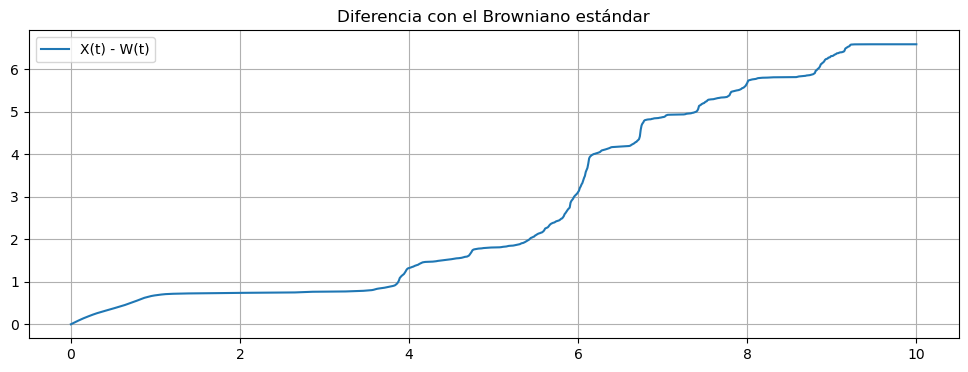

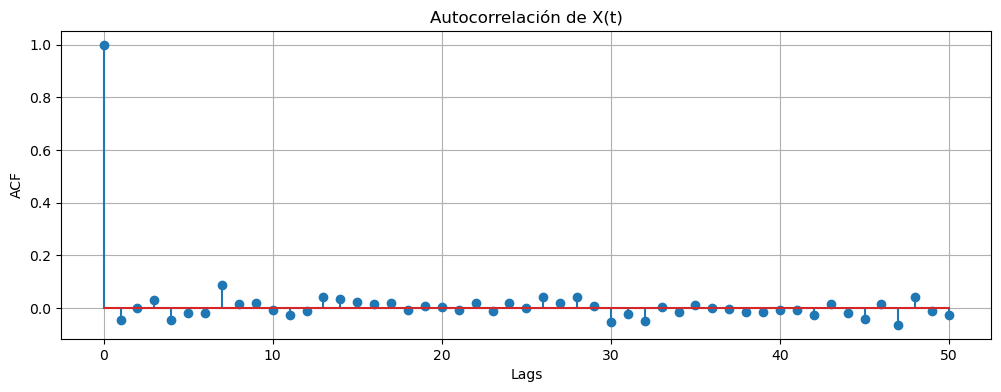

In [69]:
mu_exp = lambda t, x: np.exp(-t*x)
sigma_const = lambda t: 1

X = euler_maruyama(mu_exp, sigma_const)

# Trayectoria simulada
plt.figure(figsize=(12, 4))
plt.plot(t, X, label = 'X(t)')
plt.title("SDE: $dX_t = e^{-tx} dt + d W_t$")
plt.xlabel("t")
plt.ylabel("X(t)")
plt.grid(True)
plt.legend()
plt.show()

# Diferencia con Browniano estándar
plt.figure(figsize=(12, 4))
plt.plot(t, X - W, label='X(t) - W(t)')
plt.title("Diferencia con el Browniano estándar")
plt.grid(True)
plt.legend()
plt.show()

# Autocorrelación
acf_vals = acf(np.diff(X), nlags=50)
plt.figure(figsize=(12, 4))
plt.stem(range(len(acf_vals)), acf_vals)
plt.title("Autocorrelación de X(t)")
plt.xlabel("Lags")
plt.ylabel("ACF")
plt.grid(True)
plt.show()

##### Caso 4: $\mu(x,t) = e^{-tx}$, $\sigma(t) = 0.3 + 0.2\sin{(5t)}$

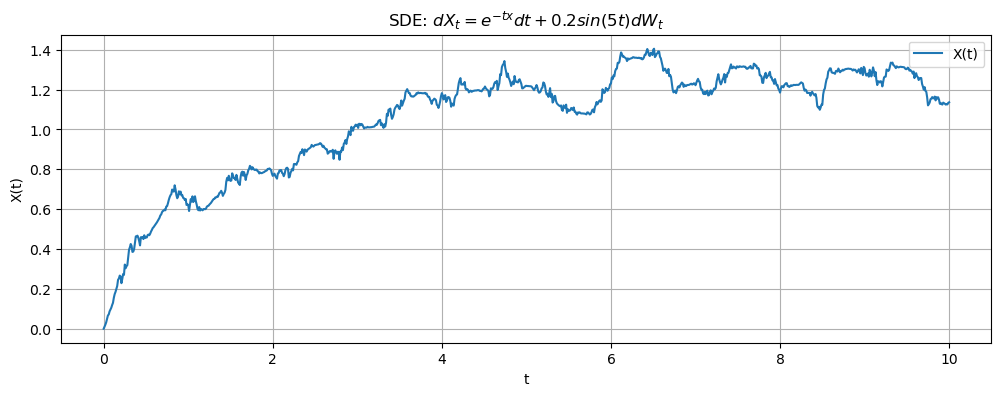

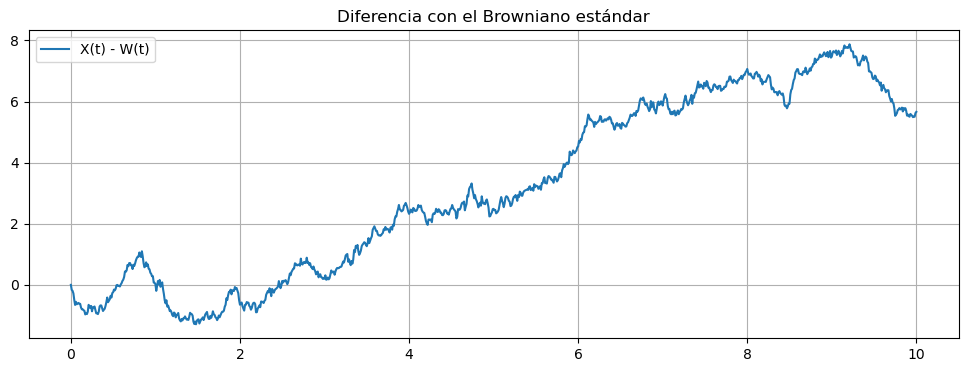

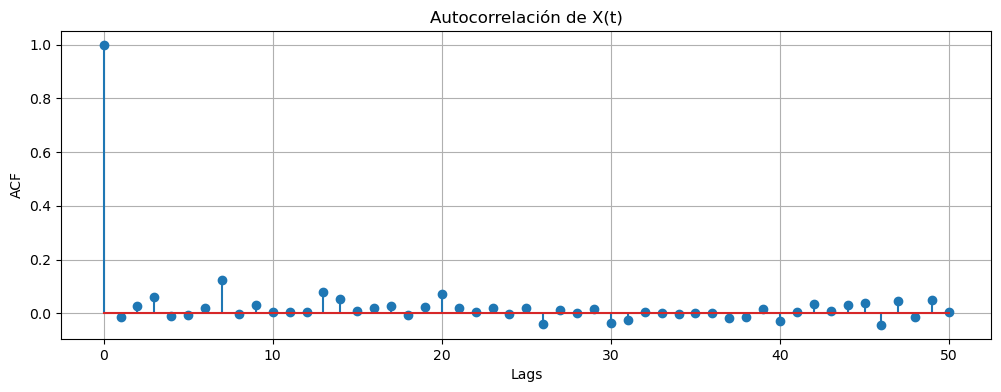

In [70]:
mu_exp = lambda t, x: np.exp(-t*x)
sigma_t = lambda t: 0.2 * np.sin(5 * t)

X = euler_maruyama(mu_exp, sigma_t)

# Trayectoria simulada
plt.figure(figsize=(12, 4))
plt.plot(t, X, label = 'X(t)')
plt.title("SDE: $dX_t = e^{-tx} dt + 0.2 sin(5t) d W_t$")
plt.xlabel("t")
plt.ylabel("X(t)")
plt.grid(True)
plt.legend()
plt.show()

# Diferencia con Browniano estándar
plt.figure(figsize=(12, 4))
plt.plot(t, X - W, label='X(t) - W(t)')
plt.title("Diferencia con el Browniano estándar")
plt.grid(True)
plt.legend()
plt.show()

# Autocorrelación
acf_vals = acf(np.diff(X), nlags=50)
plt.figure(figsize=(12, 4))
plt.stem(range(len(acf_vals)), acf_vals)
plt.title("Autocorrelación de X(t)")
plt.xlabel("Lags")
plt.ylabel("ACF")
plt.grid(True)
plt.show()